# Stage-Discharge Curve Fitting: Baton Rouge (01160)

This notebook extracts the flow-stage relationship for the Baton Rouge station from Figure 3 of the JHY2013 paper, testing both a power-law and a second-degree polynomial to handle hysteresis effects.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import Image, display, Markdown, Latex, clear_output
import requests
import pandas as pd
from io import StringIO
from datetime import datetime
import ipywidgets as widgets
import lxml

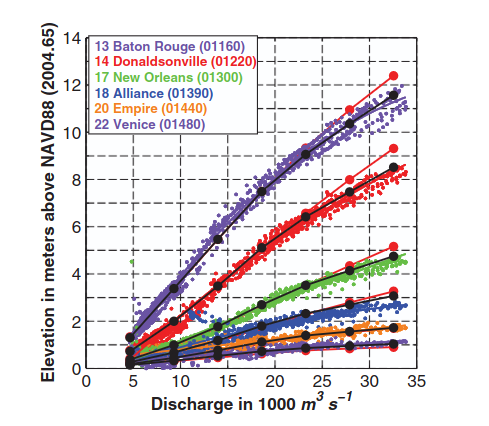

In [2]:
# Load and display the image for visual verification
display(Image(filename='rivercalc/stage_input.png'))

In [3]:
# Estimated data points for the top curve (13 Baton Rouge station)
q_data = np.array([4.8, 9.3, 13.9, 18.5, 23.3, 27.9, 32.6])
h_data = np.array([1.2, 3.4, 5.5, 7.5, 9.4, 10.9, 12.0])

In [4]:
# Define curve-fitting models
def power_law(q, a, b, c):
    return a * np.power(q, b) + c

def poly_2nd(q, a, b, c):
    return a * q**2 + b * q + c

# Perform curve fitting
popt_power, _ = curve_fit(power_law, q_data, h_data, p0=[1, 1, 0], maxfev=5000)
print(f"Power-law fit: h = {popt_power[0]:.4f} * q^{popt_power[1]:.4f} + {popt_power[2]:.4f}")
print(f"Power-law coefficients (a, b, c): {popt_power}")

popt_poly, _ = curve_fit(poly_2nd, q_data, h_data)
print(f"Polynomial fit: h = {popt_poly[0]:.4f} * q^2 + {popt_poly[1]:.4f} * q + {popt_poly[2]:.4f}")
print(f"Polynomial coefficients (a, b, c): {popt_poly}")

Power-law fit: h = 1.7847 * q^0.6277 + -3.6823
Power-law coefficients (a, b, c): [ 1.78467926  0.62774811 -3.68226147]
Polynomial fit: h = -0.0052 * q^2 + 0.5870 * q + -1.5681
Polynomial coefficients (a, b, c): [-0.00515267  0.58698511 -1.56806802]


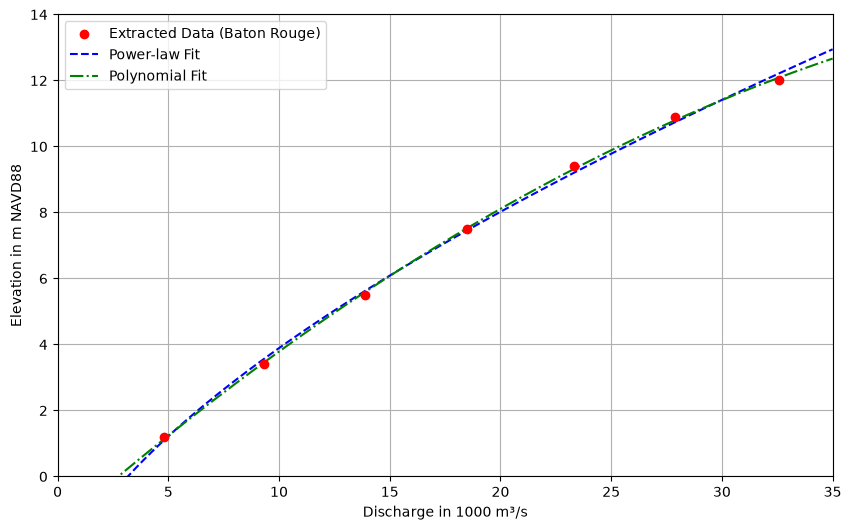

In [5]:
# Generate q_fit arrays for the fitted curves
q_fit = np.linspace(0, 35, 100)
h_fit_power = power_law(q_fit, *popt_power)
h_fit_poly = poly_2nd(q_fit, *popt_poly)

# Plot data and fitted curves
plt.figure(figsize=(10, 6))
plt.scatter(q_data, h_data, color='red', label='Extracted Data (Baton Rouge)', zorder=5)
plt.plot(q_fit, h_fit_power, '--', color='blue', label='Power-law Fit')
plt.plot(q_fit, h_fit_poly, '-.', color='green', label='Polynomial Fit')

# Formatting plot
plt.xlabel('Discharge in 1000 m³/s')
plt.ylabel('Elevation in m NAVD88')
plt.xlim(0, 35)
plt.ylim(0, 14)
plt.legend()
plt.grid(True)

plt.show()

In [6]:
# Inverted functions: Discharge q as a function of Elevation/Stage h
a_p, b_p, c_p = popt_power
a_2, b_2, c_2 = popt_poly

def q_from_h_power(h):
    """Calculates discharge q (in kcms, i.e., 1000 m³/s) from stage h (in m NAVD88) using inverted power-law fit."""
    return ((h - c_p) / a_p) ** (1 / b_p)

def q_from_h_poly(h):
    """Calculates discharge q (in kcms, i.e., 1000 m³/s) from stage h (in m NAVD88) using inverted 2nd-degree polynomial fit."""
    discriminant = b_2**2 - 4 * a_2 * (c_2 - h)
    return (-b_2 + np.sqrt(discriminant)) / (2 * a_2)

# Print formulas
print("=== Inverted Stage-Discharge Formulas: q(h) ===")
print(f"1. Power-Law:    q(h) = ((h + {-c_p:.4f}) / {a_p:.4f}) ** {1/b_p:.4f}")
print(f"2. Polynomial:   q(h) = (-({b_2:.4f}) + sqrt(({b_2:.4f})^2 - 4*({a_2:.4f})*({c_2:.4f} - h))) / (2 * ({a_2:.4f}))")

# Display LaTeX formatted formulas under the plot
display(Markdown(f"""
### Fitted Equations for Discharge $q(h)$ given Elevation $h$:

**1. Power-Law Model:**
$$q(h) = \\left( \\frac{{h + {-c_p:.4f}}}{{{a_p:.4f}}} \\right)^{{{1/b_p:.4f}}}$$

**2. 2nd-Degree Polynomial Model:**
$$q(h) = \\frac{{-({b_2:.4f}) + \\sqrt{{({b_2:.4f})^2 - 4({a_2:.4f})({c_2:.4f} - h)}}}}{{2({a_2:.4f})}}$$
"""))

# Example calculation for h = 7.5 m NAVD88
h_example = 7.5
print(f"Example calculation at h = {h_example} m NAVD88:")
print(f"  Power-Law Discharge q({h_example}) = {q_from_h_power(h_example):.2f} kcms")
print(f"  Polynomial Discharge q({h_example}) = {q_from_h_poly(h_example):.2f} kcms")

=== Inverted Stage-Discharge Formulas: q(h) ===
1. Power-Law:    q(h) = ((h + 3.6823) / 1.7847) ** 1.5930
2. Polynomial:   q(h) = (-(0.5870) + sqrt((0.5870)^2 - 4*(-0.0052)*(-1.5681 - h))) / (2 * (-0.0052))



### Fitted Equations for Discharge $q(h)$ given Elevation $h$:

**1. Power-Law Model:**
$$q(h) = \left( \frac{h + 3.6823}{1.7847} \right)^{1.5930}$$

**2. 2nd-Degree Polynomial Model:**
$$q(h) = \frac{-(0.5870) + \sqrt{(0.5870)^2 - 4(-0.0052)(-1.5681 - h)}}{2(-0.0052)}$$


Example calculation at h = 7.5 m NAVD88:
  Power-Law Discharge q(7.5) = 18.60 kcms
  Polynomial Discharge q(7.5) = 18.43 kcms


### Automated Data Fetching and Stage-to-Discharge/Flow Conversion

The function below fetches historical daily stage/elevation data directly from the USACE [RiverGages portal](https://rivergages.mvr.usace.army.mil/WaterControl/stationinfo2.cfm?sid=01160&fid=RCKI2&dt=S&pcode=HG) for Baton Rouge (01160).

**Default Parameters:**
- **Start Date:** `01/01/1987`
- **End Date:** `12/31/2026`
- **Station ID:** `01160` (Mississippi River at Baton Rouge)

**Processing & Unit Conversions:**
1. Submits an HTTP POST request to retrieve historical daily readings.
2. Applies NAVD88 datum correction (`-0.71 ft`) to convert NGVD 29 values to NAVD88.
3. Converts feet to meters (`* 0.3048`).
4. Computes estimated river discharge (`kcms`, i.e., $1000\text{ m}^3/\text{s}$) using the fitted model.
5. Converts discharge into standard Flow ($m^3/s$) and Flow ($cfs$).

In [7]:
def fetch_rivergages_data(start_date='01/01/1987', end_date='12/31/2026', sid='01160', model='power'):
    """
    Fetches historical stage/elevation data from RiverGages.com, applies NAVD88
    datum correction (-0.71 ft), converts to meters, and calculates discharge in kcms and flow in m³/s and cfs.
    """
    url = f"https://rivergages.mvr.usace.army.mil/WaterControl/shefgraph-historic.cfm?sid={sid}"
    s_dt = datetime.strptime(start_date, '%m/%d/%Y')
    e_dt = datetime.strptime(end_date, '%m/%d/%Y')

    payload = {
        'fld_param': 'HG',
        'fld_mon1': s_dt.strftime('%m'),
        'fld_day1': s_dt.strftime('%d'),
        'fld_year1': s_dt.strftime('%Y'),
        'fld_mon2': e_dt.strftime('%m'),
        'fld_day2': e_dt.strftime('%d'),
        'fld_year2': e_dt.strftime('%Y'),
        'fld_displaytype': 'E',
        'fld_from1': start_date,
        'fld_to1': end_date,
        'fld_type1': 'Table'
    }

    print(f"Fetching data for station {sid} from {start_date} to {end_date}...")
    response = requests.post(url, data=payload)
    tables = pd.read_html(StringIO(response.text))

    df_raw = None
    for tbl in tables:
        if (tbl.astype(str).values == 'Date / Time').any():
            hdr_mask = (tbl == 'Date / Time').any(axis=1)
            hdr_idx = tbl[hdr_mask].index[0]
            tbl.columns = tbl.iloc[hdr_idx]
            df_raw = tbl.iloc[hdr_idx + 1:].copy()
            df_raw.columns = [str(c).strip() for c in df_raw.columns]
            break

    if df_raw is None:
        raise ValueError("Could not find data table on RiverGages page.")

    val_col = df_raw.columns[1]
    df = df_raw.copy()
    df['Date / Time'] = pd.to_datetime(df['Date / Time'], errors='coerce')
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce')
    df = df.dropna(subset=['Date / Time', val_col]).reset_index(drop=True)

    # Datum Shift (-0.71 ft) & Unit Conversions
    df['Elevation NAVD88 (ft)'] = df[val_col] - 0.71
    df['Elevation NAVD88 (m)'] = df['Elevation NAVD88 (ft)'] * 0.3048

    # Compute Discharge & Flow
    if model == 'power':
        df['Discharge (kcms)'] = q_from_h_power(df['Elevation NAVD88 (m)'])
    elif model == 'poly':
        df['Discharge (kcms)'] = q_from_h_poly(df['Elevation NAVD88 (m)'])
    else:
        raise ValueError("Model must be 'power' or 'poly'")

    df['Flow (m³/s)'] = df['Discharge (kcms)'] * 1000.0
    df['Flow (cfs)'] = df['Flow (m³/s)'] * 35.3146667

    return df

# Fetch full dataset from 1987 to 2026
df_discharge = fetch_rivergages_data(start_date='01/01/1987', end_date='12/31/2026', model='power')
df_discharge.head()

Fetching data for station 01160 from 01/01/1987 to 12/31/2026...


,Date / Time,Elevation (Ft),Elevation NAVD88 (ft),Elevation NAVD88 (m),Discharge (kcms),Flow (m³/s),Flow (cfs)
0,1987-03-28,28.52,27.81,8.476488,21.256366,21256.366428,750661.495641
1,1987-03-29,28.22,27.51,8.385048,21.002281,21002.280596,741688.539176
2,1987-03-30,28.09,27.38,8.345424,20.892530,20892.530302,737812.744126
3,1987-03-31,27.81,27.10,8.260080,20.656873,20656.872933,729490.582688
4,1987-04-01,27.45,26.74,8.150352,20.355350,20355.349611,718842.387083


### Interactive River Stage and Flow Hydrograph (1987 - 2026)

The interactive figure below displays two stacked time-series panels sharing the X-axis:
1. **Top Panel:** Raw, uncorrected river Stage/Elevation in feet (NGVD 29) directly as fetched from USACE RiverGages.
2. **Bottom Panel:** Estimated River Discharge (`kcms`) calculated using the fitted JHY2013 power-law formula.

**Interactive Controls:**
Use the `Shade Start` and `Shade End` date pickers below to select any date window (e.g., Hurricane Katrina in late August 2005). A **red shaded highlight** will dynamically overlay the selected period across both panels.

In [ ]:
def plot_interactive_hydrograph(start_shade, end_shade):
    """
    Plots dual-panel timeseries of raw stage (top) and calculated discharge in kcms (bottom),
    with red shading across the user-selected date range and mean rate display.
    """
    clear_output(wait=True)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    raw_col = df_discharge.columns[1]

    # --- Top Panel: Raw Stage (NGVD 29) ---
    ax1.plot(df_discharge['Date / Time'], df_discharge[raw_col], color='forestgreen', linewidth=1, label='Raw Stage (ft NGVD 29)')
    ax1.set_ylabel('Raw Stage (ft NGVD 29)', color='forestgreen', fontsize=12)
    ax1.set_title('Mississippi River at Baton Rouge (01160)\nRaw Stage & Calculated Discharge (1987 - 2026)', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend(loc='upper right')

    # --- Bottom Panel: Calculated Discharge ---
    ax2.plot(df_discharge['Date / Time'], df_discharge['Discharge (kcms)'], color='tab:blue', linewidth=1, label='Discharge (kcms)')
    ax2.set_ylabel('Discharge (kcms)', color='tab:blue', fontsize=12)
    ax2.set_xlabel('Year', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend(loc='upper right')

    # --- Red Shading Overlay & Average Calculation ---
    s_date = pd.to_datetime(start_shade)
    e_date = pd.to_datetime(end_shade)

    if pd.notnull(s_date) and pd.notnull(e_date) and s_date < e_date:
        ax1.axvspan(s_date, e_date, color='red', alpha=0.3, label=f'Highlighted Period')
        ax2.axvspan(s_date, e_date, color='red', alpha=0.3)
        ax1.legend(loc='upper right')

        # Calculate mean for selected window
        mask = (df_discharge['Date / Time'] >= s_date) & (df_discharge['Date / Time'] <= e_date)
        period_data = df_discharge.loc[mask]

        if not period_data.empty:
            avg_stage = period_data[raw_col].mean()
            avg_q = period_data['Discharge (kcms)'].mean()
            avg_cfs = period_data['Flow (cfs)'].mean()

            stats_text = (
                f"Selected Period ({s_date.strftime('%Y-%m-%d')} to {e_date.strftime('%Y-%m-%d')}):\n"
                f"• Mean Stage: {avg_stage:.2f} ft\n"
                f"• Mean Discharge: {avg_q:.2f} kcms ({avg_cfs:,.0f} cfs)"
            )

            ax2.text(
                0.02, 0.88, stats_text,
                transform=ax2.transAxes,
                fontsize=11,
                verticalalignment='top',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='red', linewidth=1.5)
            )

    fig.tight_layout()
    plt.show()

# Default Date Pickers (e.g. Hurricane Katrina: Aug 20, 2005 - Sep 10, 2005)
start_picker = widgets.DatePicker(description='Shade Start', value=pd.to_datetime('2005-08-20').date())
end_picker = widgets.DatePicker(description='Shade End', value=pd.to_datetime('2005-09-10').date())

# Display Interactive Widget
widgets.interact(plot_interactive_hydrograph, start_shade=start_picker, end_shade=end_picker);



interactive(children=(DatePicker(value=datetime.date(2005, 8, 20), description='Shade Start', step=1), DatePic…

ValueError: Date ordinal -755492.0666666668 converts to -099-07-14T22:23:59.999992 (using epoch 1970-01-01T00:00:00), but Matplotlib dates must be between year 0001 and 9999.

ValueError: Date ordinal -755492.0666666668 converts to -099-07-14T22:23:59.999992 (using epoch 1970-01-01T00:00:00), but Matplotlib dates must be between year 0001 and 9999.

<Figure size 1400x800 with 2 Axes>